In [3]:
import os
import math
import random
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.distributed as dist

from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data import Dataset, DataLoader, DistributedSampler

from torchvision import transforms
from torchvision.utils import make_grid

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [4]:
INPUT_DIR = Path("/kaggle/input")

image_paths = sorted(INPUT_DIR.rglob("*.png"))

print("Total PNG images:", len(image_paths))
print("\nFirst 5 images:")

for path in image_paths[:5]:
    print(path)

IMAGE_DIR = image_paths[0].parent if image_paths else None

print("\nImage directory:", IMAGE_DIR)

Total PNG images: 3744

First 5 images:
/kaggle/input/datasets/tbouhafa/potsdam-train/data/processed/train/images/top_potsdam_2_10_r00_c00.png
/kaggle/input/datasets/tbouhafa/potsdam-train/data/processed/train/images/top_potsdam_2_10_r00_c01.png
/kaggle/input/datasets/tbouhafa/potsdam-train/data/processed/train/images/top_potsdam_2_10_r00_c02.png
/kaggle/input/datasets/tbouhafa/potsdam-train/data/processed/train/images/top_potsdam_2_10_r00_c03.png
/kaggle/input/datasets/tbouhafa/potsdam-train/data/processed/train/images/top_potsdam_2_10_r00_c04.png

Image directory: /kaggle/input/datasets/tbouhafa/potsdam-train/data/processed/train/images


In [5]:
sample_paths = random.sample(image_paths, min(8, len(image_paths)))

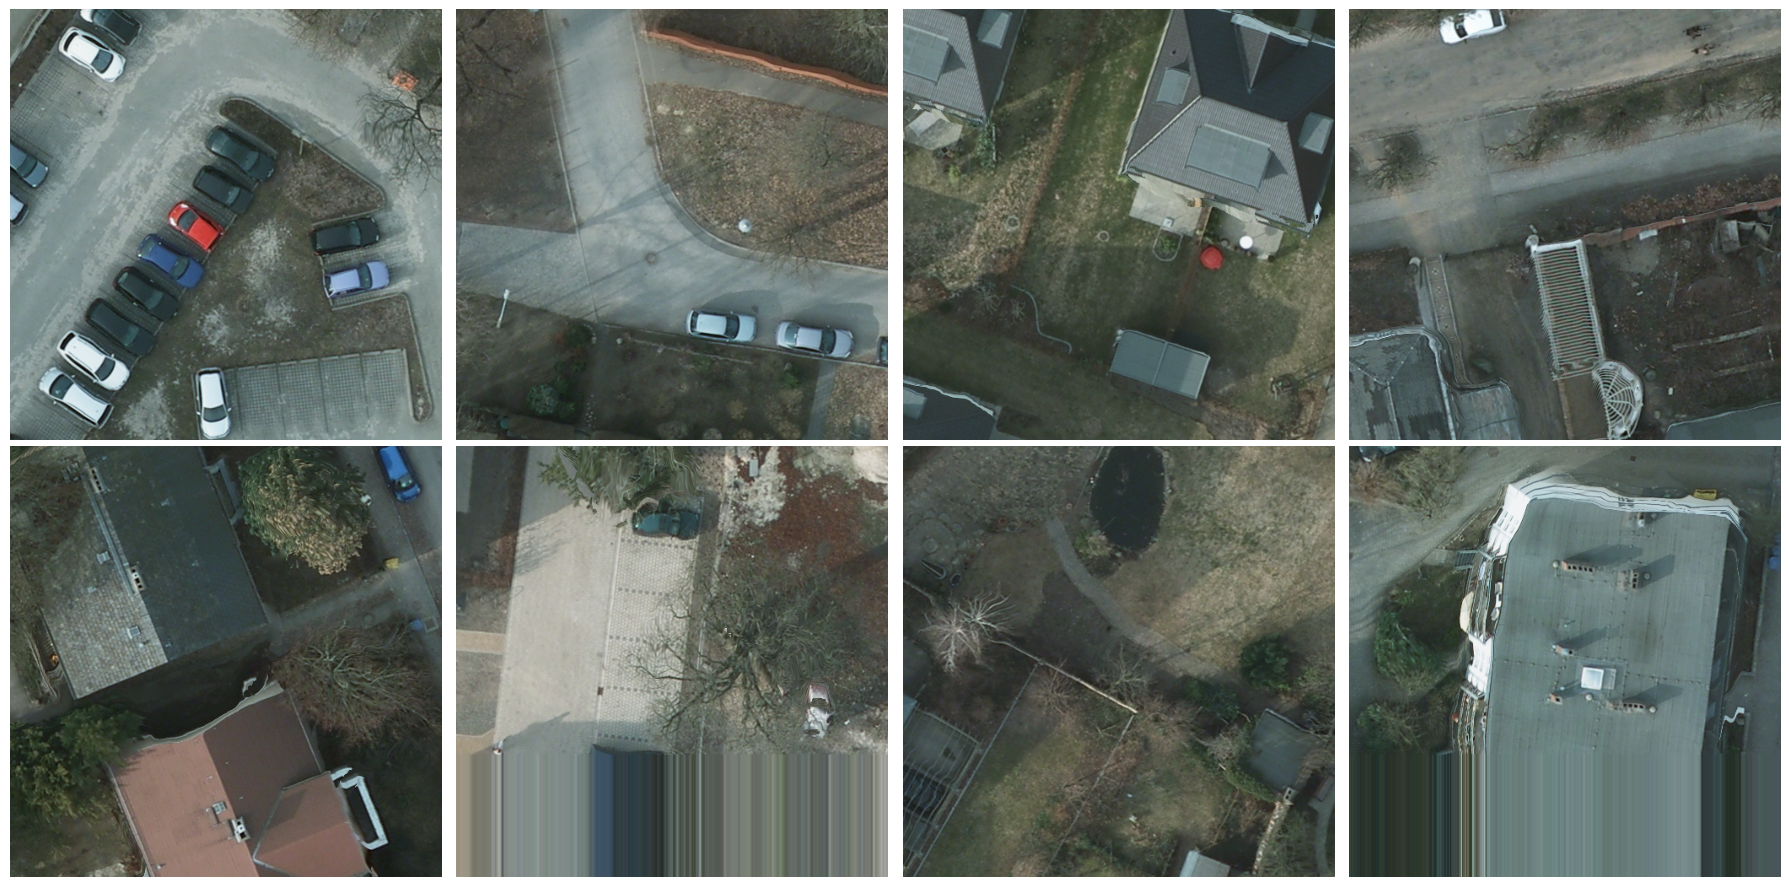

Saved: /kaggle/working/potsdam_samples.zip


In [6]:
import shutil

OUTPUT_DIR = Path("/kaggle/working/potsdam_samples")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for i, path in enumerate(sample_paths):
    shutil.copy(path, OUTPUT_DIR / path.name)

plt.figure(figsize=(18, 9))

for i, path in enumerate(sample_paths):
    plt.subplot(2, 4, i + 1)
    plt.imshow(Image.open(path).convert("RGB"))
    plt.axis("off")

plt.tight_layout()

plt.savefig(OUTPUT_DIR / "potsdam_samples_grid.png", dpi=200, bbox_inches="tight")
plt.show()

shutil.make_archive(
    "/kaggle/working/potsdam_samples",
    "zip",
    OUTPUT_DIR
)

print("Saved:", "/kaggle/working/potsdam_samples.zip")


In [7]:
IMAGE_SIZE = 512
BATCH_SIZE = 16
NUM_WORKERS = 4

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

class PotsdamDataset(Dataset):
    def __init__(self, image_paths, transform=None):
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = Image.open(self.image_paths[index]).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image

train_dataset = PotsdamDataset(image_paths, transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
    persistent_workers=True
)

print("Training images:", len(train_dataset))
print("Batches per epoch:", len(train_loader))
print("Batch shape:", next(iter(train_loader)).shape)

Training images: 3744
Batches per epoch: 234
Batch shape: torch.Size([16, 3, 512, 512])


In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [9]:
TIMESTEPS = 1000

def sigmoid_beta_schedule(timesteps, start=-3, end=3, tau=1):
    steps = timesteps + 1
    t = torch.linspace(0, timesteps, steps, dtype=torch.float64) / timesteps

    v_start = torch.tensor(start / tau).sigmoid()
    v_end = torch.tensor(end / tau).sigmoid()

    alphas_cumprod = (
        -((t * (end - start) + start) / tau).sigmoid() + v_end
    ) / (v_end - v_start)

    alphas_cumprod = alphas_cumprod / alphas_cumprod[0]

    betas = 1.0 - (alphas_cumprod[1:] / alphas_cumprod[:-1])

    return torch.clamp(betas, 0, 0.999)


betas = sigmoid_beta_schedule(TIMESTEPS).float().to(device)

alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)

sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)

print("Timesteps:", TIMESTEPS)
print("Beta shape:", betas.shape)
print("Beta range:", betas.min().item(), betas.max().item())
print("Final alpha cumulative product:", alphas_cumprod[-1].item())

Timesteps: 1000
Beta shape: torch.Size([1000])
Beta range: 0.00030027920729480684 0.9990000128746033
Final alpha cumulative product: 3.002827213549608e-07


In [10]:
def extract(a, t, x_shape):
    out = a.gather(0, t)
    return out.reshape(t.shape[0], *((1,) * (len(x_shape) - 1)))


def q_sample(x_start, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x_start)

    sqrt_alpha = extract(sqrt_alphas_cumprod, t, x_start.shape)
    sqrt_one_minus_alpha = extract(sqrt_one_minus_alphas_cumprod, t, x_start.shape)

    return sqrt_alpha * x_start + sqrt_one_minus_alpha * noise

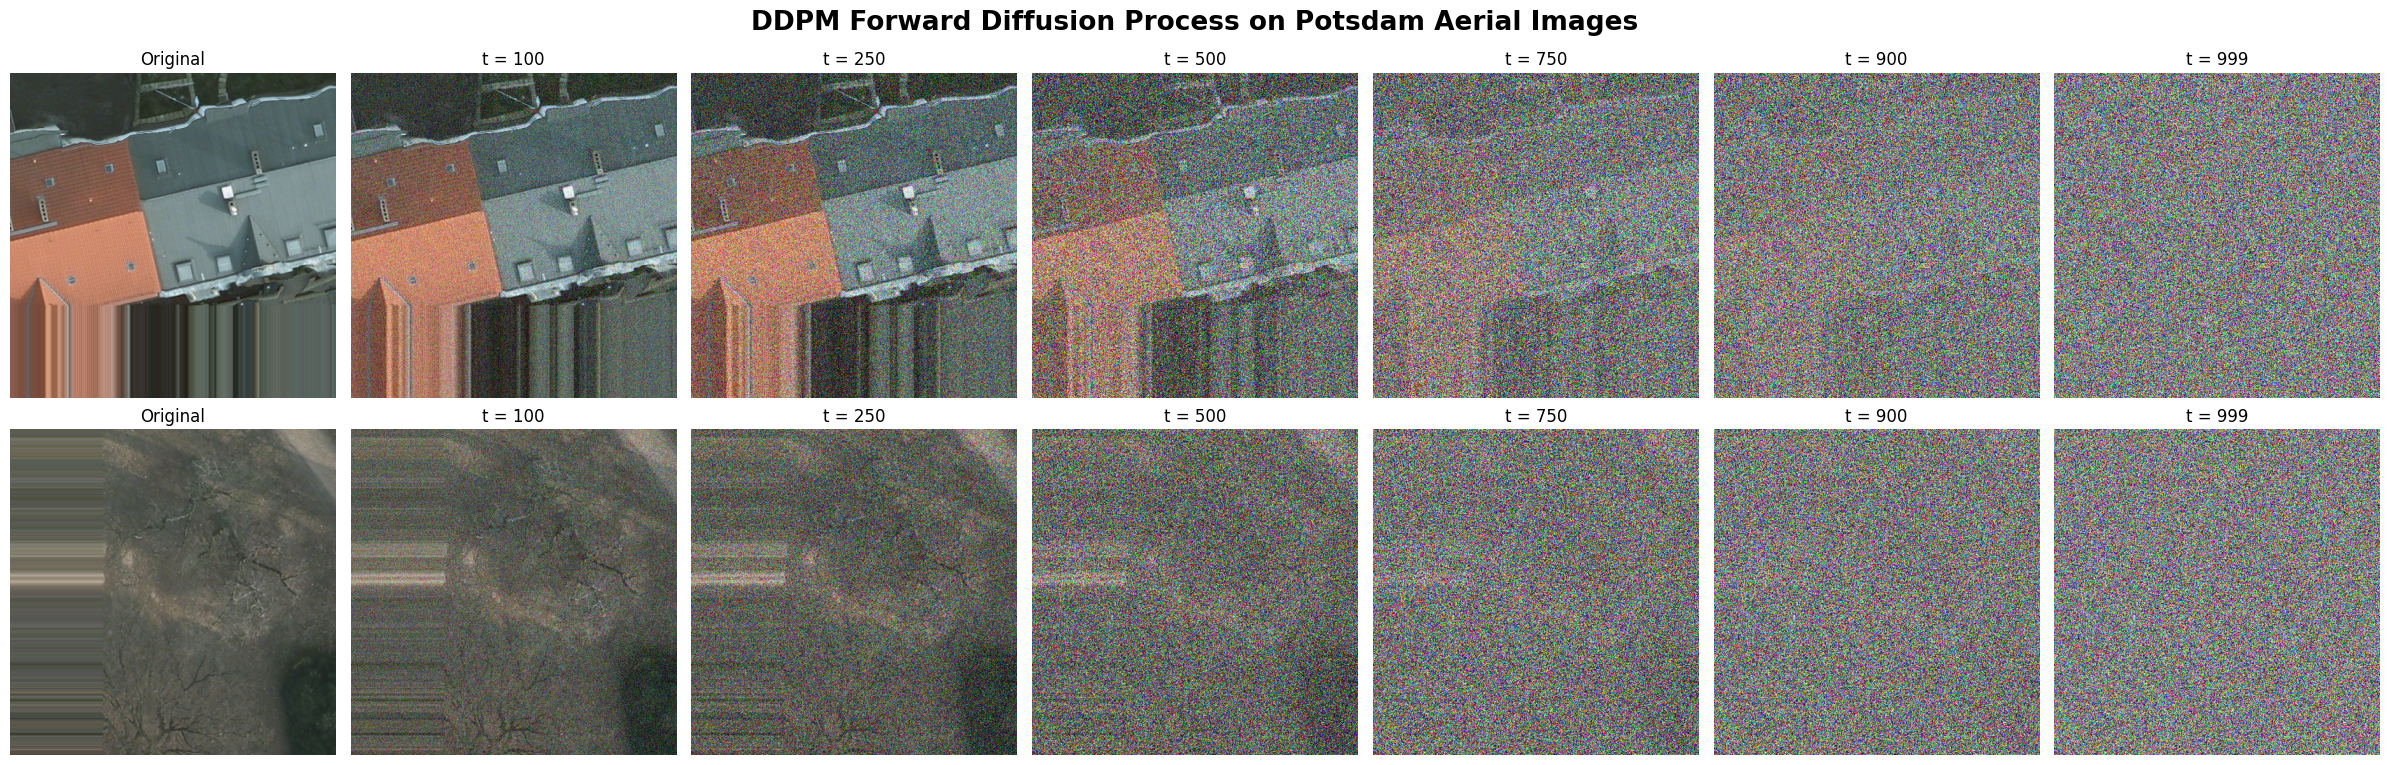

Saved visualization: /kaggle/working/forward_diffusion_visualization.png


In [11]:
sample_paths = random.sample(image_paths, 2)

timesteps_to_show = [100, 250, 500, 750, 900, 999]

fig, axes = plt.subplots(2, 7, figsize=(24, 8))

for row, sample_path in enumerate(sample_paths):
    x_start = transform(Image.open(sample_path).convert("RGB"))
    x_start = x_start.unsqueeze(0).to(device)

    fixed_noise = torch.randn_like(x_start)

    original = (x_start[0].cpu() * 0.5 + 0.5).clamp(0, 1)

    axes[row, 0].imshow(original.permute(1, 2, 0))
    axes[row, 0].set_title("Original", fontsize=12)

    with torch.no_grad():
        for col, timestep in enumerate(timesteps_to_show, start=1):
            t = torch.tensor([timestep], device=device)
            noisy_image = q_sample(x_start, t, fixed_noise)

            noisy_image = (noisy_image[0].cpu() * 0.5 + 0.5).clamp(0, 1)

            axes[row, col].imshow(noisy_image.permute(1, 2, 0))
            axes[row, col].set_title(f"t = {timestep}", fontsize=12)

    axes[row, 0].set_ylabel(
        sample_path.stem,
        fontsize=9,
        rotation=90,
        labelpad=15
    )

for ax in axes.flat:
    ax.axis("off")

fig.suptitle(
    "DDPM Forward Diffusion Process on Potsdam Aerial Images",
    fontsize=19,
    fontweight="bold"
)

plt.tight_layout()

OUTPUT_IMAGE = "/kaggle/working/forward_diffusion_visualization.png"

plt.savefig(
    OUTPUT_IMAGE,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved visualization:", OUTPUT_IMAGE)

In [12]:
from einops.layers.torch import Rearrange

In [13]:
def exists(x):
    return x is not None


def default(val, d):
    if exists(val):
        return val
    return d() if callable(d) else d


def cast_tuple(t, length=1):
    if isinstance(t, tuple):
        return t
    return (t,) * length


def divisible_by(numer, denom):
    return (numer % denom) == 0


class RMSNorm(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.g = nn.Parameter(torch.ones(1, dim, 1, 1))

    def forward(self, x):
        return F.normalize(x, dim=1) * self.g * (x.shape[1] ** 0.5)


def Upsample(dim, dim_out=None):
    return nn.Sequential(
        nn.Upsample(scale_factor=2, mode="nearest"),
        nn.Conv2d(dim, default(dim_out, dim), 3, padding=1)
    )


def Downsample(dim, dim_out=None):
    return nn.Sequential(
        Rearrange("b c (h p1) (w p2) -> b (c p1 p2) h w", p1=2, p2=2),
        nn.Conv2d(dim * 4, default(dim_out, dim), 1)
    )


class SinusoidalPosEmb(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, x):
        device = x.device
        half_dim = self.dim // 2
        emb = math.log(10000) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=device) * -emb)
        emb = x[:, None] * emb[None, :]
        emb = torch.cat((emb.sin(), emb.cos()), dim=-1)
        return emb

In [14]:
class Block(nn.Module):
    def __init__(self, dim, dim_out, groups=8):
        super().__init__()
        self.proj = nn.Conv2d(dim, dim_out, 3, padding=1)
        self.norm = nn.GroupNorm(groups, dim_out)
        self.act = nn.SiLU()

    def forward(self, x, scale_shift=None):
        x = self.proj(x)
        x = self.norm(x)

        if exists(scale_shift):
            scale, shift = scale_shift
            x = x * (scale + 1) + shift

        x = self.act(x)
        return x


class ResnetBlock(nn.Module):
    def __init__(self, dim, dim_out, time_emb_dim=None, groups=8):
        super().__init__()

        self.mlp = nn.Sequential(
            nn.SiLU(),
            nn.Linear(time_emb_dim, dim_out * 2)
        ) if exists(time_emb_dim) else None

        self.block1 = Block(dim, dim_out, groups=groups)
        self.block2 = Block(dim_out, dim_out, groups=groups)
        self.res_conv = nn.Conv2d(dim, dim_out, 1) if dim != dim_out else nn.Identity()

    def forward(self, x, time_emb=None):
        scale_shift = None

        if exists(self.mlp) and exists(time_emb):
            time_emb = self.mlp(time_emb)
            time_emb = rearrange(time_emb, "b c -> b c 1 1")
            scale_shift = time_emb.chunk(2, dim=1)

        h = self.block1(x, scale_shift=scale_shift)
        h = self.block2(h)

        return h + self.res_conv(x)

In [15]:
class LinearAttention(nn.Module):
    def __init__(self, dim, heads=4, dim_head=32):
        super().__init__()

        self.scale = dim_head ** -0.5
        self.heads = heads
        hidden_dim = dim_head * heads

        self.norm = RMSNorm(dim)
        self.to_qkv = nn.Conv2d(dim, hidden_dim * 3, 1, bias=False)

        self.to_out = nn.Sequential(
            nn.Conv2d(hidden_dim, dim, 1),
            RMSNorm(dim)
        )

    def forward(self, x):
        b, c, h, w = x.shape

        x = self.norm(x)

        qkv = self.to_qkv(x).chunk(3, dim=1)

        q, k, v = map(
            lambda t: rearrange(
                t, "b (h c) x y -> b h c (x y)", h=self.heads
            ),
            qkv
        )

        q = q.softmax(dim=-2)
        k = k.softmax(dim=-1)

        q = q * self.scale

        context = torch.einsum(
            "b h d n, b h e n -> b h d e", k, v
        )

        out = torch.einsum(
            "b h d e, b h d n -> b h e n", context, q
        )

        out = rearrange(
            out, "b h c (x y) -> b (h c) x y",
            h=self.heads, x=h, y=w
        )

        return self.to_out(out)

In [16]:
class Attention(nn.Module):
    def __init__(
        self,
        dim,
        heads=4,
        dim_head=32,
        flash=False
    ):
        super().__init__()

        self.heads = heads
        hidden_dim = dim_head * heads

        self.norm = RMSNorm(dim)
        self.to_qkv = nn.Conv2d(
            dim, hidden_dim * 3, 1, bias=False
        )
        self.to_out = nn.Conv2d(hidden_dim, dim, 1)

    def forward(self, x):
        b, c, h, w = x.shape

        x = self.norm(x)

        qkv = self.to_qkv(x).chunk(3, dim=1)

        q, k, v = map(
            lambda t: rearrange(
                t, "b (heads d) h w -> b heads (h w) d",
                heads=self.heads
            ),
            qkv
        )

        out = F.scaled_dot_product_attention(q, k, v)

        out = rearrange(
            out, "b heads (h w) d -> b (heads d) h w",
            h=h, w=w
        )

        return self.to_out(out)

In [17]:
class RandomOrLearnedSinusoidalPosEmb(nn.Module):
    def __init__(self, dim, is_random=False):
        super().__init__()
        assert divisible_by(dim, 2)

        half_dim = dim // 2

        self.weights = nn.Parameter(
            torch.randn(half_dim),
            requires_grad=not is_random
        )

    def forward(self, x):
        x = rearrange(x, "b -> b 1")

        freqs = (
            x * rearrange(self.weights, "d -> 1 d")
            * 2 * math.pi
        )

        fouriered = torch.cat(
            (freqs.sin(), freqs.cos()),
            dim=-1
        )

        return torch.cat((x, fouriered), dim=-1)


class Unet(nn.Module):
    def __init__(
        self,
        dim,
        init_dim=None,
        out_dim=None,
        dim_mults=(1, 2, 4, 8),
        channels=3,
        self_condition=False,
        resnet_block_groups=8,
        learned_variance=False,
        learned_sinusoidal_cond=False,
        random_fourier_features=False,
        learned_sinusoidal_dim=16,
        attn_dim_head=32,
        attn_heads=4,
        full_attn=(False, False, False, True),
        flash_attn=False
    ):
        super().__init__()

        self.channels = channels
        self.self_condition = self_condition

        input_channels = channels * (2 if self_condition else 1)

        init_dim = default(init_dim, dim)

        self.init_conv = nn.Conv2d(
            input_channels, init_dim, 7, padding=3
        )

        dims = [init_dim, *map(lambda m: dim * m, dim_mults)]
        in_out = list(zip(dims[:-1], dims[1:]))

        block_klass = lambda dim_in, dim_out, **kwargs: ResnetBlock(
            dim_in,
            dim_out,
            groups=resnet_block_groups,
            **kwargs
        )

        time_dim = dim * 4

        self.random_or_learned_sinusoidal_cond = (
            learned_sinusoidal_cond or random_fourier_features
        )

        if self.random_or_learned_sinusoidal_cond:
            sinu_pos_emb = RandomOrLearnedSinusoidalPosEmb(
                learned_sinusoidal_dim,
                random_fourier_features
            )
            fourier_dim = learned_sinusoidal_dim + 1
        else:
            sinu_pos_emb = SinusoidalPosEmb(dim)
            fourier_dim = dim

        self.time_mlp = nn.Sequential(
            sinu_pos_emb,
            nn.Linear(fourier_dim, time_dim),
            nn.GELU(),
            nn.Linear(time_dim, time_dim)
        )

        num_stages = len(dim_mults)

        full_attn = cast_tuple(full_attn, num_stages)
        attn_heads = cast_tuple(attn_heads, num_stages)
        attn_dim_head = cast_tuple(attn_dim_head, num_stages)

        assert len(full_attn) == len(dim_mults)

        FullAttention = lambda dim, **kwargs: Attention(
            dim,
            flash=flash_attn,
            **kwargs
        )

        self.downs = nn.ModuleList([])
        self.ups = nn.ModuleList([])

        num_resolutions = len(in_out)

        for ind, (
            (dim_in, dim_out),
            layer_full_attn,
            layer_attn_heads,
            layer_attn_dim_head
        ) in enumerate(zip(
            in_out,
            full_attn,
            attn_heads,
            attn_dim_head
        )):

            is_last = ind >= (num_resolutions - 1)

            attn_klass = (
                FullAttention if layer_full_attn
                else LinearAttention
            )

            self.downs.append(nn.ModuleList([
                block_klass(
                    dim_in, dim_in, time_emb_dim=time_dim
                ),
                block_klass(
                    dim_in, dim_in, time_emb_dim=time_dim
                ),
                attn_klass(
                    dim_in,
                    dim_head=layer_attn_dim_head,
                    heads=layer_attn_heads
                ),
                Downsample(dim_in, dim_out)
                if not is_last
                else nn.Conv2d(dim_in, dim_out, 3, padding=1)
            ]))

        mid_dim = dims[-1]

        self.mid_block1 = block_klass(
            mid_dim, mid_dim, time_emb_dim=time_dim
        )

        self.mid_attn = FullAttention(
            mid_dim,
            heads=attn_heads[-1],
            dim_head=attn_dim_head[-1]
        )

        self.mid_block2 = block_klass(
            mid_dim, mid_dim, time_emb_dim=time_dim
        )

        for ind, (
            (dim_in, dim_out),
            layer_full_attn,
            layer_attn_heads,
            layer_attn_dim_head
        ) in enumerate(zip(
            *map(reversed, (
                in_out,
                full_attn,
                attn_heads,
                attn_dim_head
            ))
        )):

            is_last = ind == (len(in_out) - 1)

            attn_klass = (
                FullAttention if layer_full_attn
                else LinearAttention
            )

            self.ups.append(nn.ModuleList([
                block_klass(
                    dim_out + dim_in,
                    dim_out,
                    time_emb_dim=time_dim
                ),
                block_klass(
                    dim_out + dim_in,
                    dim_out,
                    time_emb_dim=time_dim
                ),
                attn_klass(
                    dim_out,
                    dim_head=layer_attn_dim_head,
                    heads=layer_attn_heads
                ),
                Upsample(dim_out, dim_in)
                if not is_last
                else nn.Conv2d(dim_out, dim_in, 3, padding=1)
            ]))

        default_out_dim = channels * (
            1 if not learned_variance else 2
        )

        self.out_dim = default(out_dim, default_out_dim)

        self.final_res_block = block_klass(
            dim * 2,
            dim,
            time_emb_dim=time_dim
        )

        self.final_conv = nn.Conv2d(
            dim, self.out_dim, 1
        )

    @property
    def downsample_factor(self):
        return 2 ** (len(self.downs) - 1)

    def forward(self, x, time, x_self_cond=None):

        assert all(
            divisible_by(d, self.downsample_factor)
            for d in x.shape[-2:]
        ), (
            f"Input dimensions {x.shape[-2:]} must be "
            f"divisible by {self.downsample_factor}"
        )

        if self.self_condition:
            x_self_cond = default(
                x_self_cond,
                lambda: torch.zeros_like(x)
            )
            x = torch.cat((x_self_cond, x), dim=1)

        height, width = x.shape[2:]

        x = self.init_conv(x)
        r = x.clone()

        t = self.time_mlp(time)

        h = []
        out_feat = []

        for block1, block2, attn, downsample in self.downs:
            x = block1(x, t)
            h.append(x)

            x = block2(x, t)
            x = attn(x) + x
            h.append(x)

            x = downsample(x)

        scale = 16

        x = self.mid_block1(x, t)
        x = self.mid_attn(x) + x
        x = self.mid_block2(x, t)

        out_feat.append(
            F.interpolate(
                x,
                size=(height // scale, width // scale),
                mode="bilinear",
                align_corners=True
            )
        )

        for block1, block2, attn, upsample in self.ups:
            x = torch.cat((x, h.pop()), dim=1)
            x = block1(x, t)

            x = torch.cat((x, h.pop()), dim=1)
            x = block2(x, t)

            x = attn(x) + x
            x = upsample(x)

            out_feat.append(
                F.interpolate(
                    x,
                    size=(height // scale, width // scale),
                    mode="bilinear",
                    align_corners=True
                )
            )

        x = torch.cat((x, r), dim=1)
        x = self.final_res_block(x, t)

        if self.training:
            return self.final_conv(x)
        else:
            return self.final_conv(x), out_feat

In [18]:
unet = Unet(
    dim=32,
    dim_mults=(1, 2, 4, 8),
    channels=3,
    resnet_block_groups=8,
    self_condition=False
).to(device)

print("U-Net initialized successfully")
print("Parameters:", sum(p.numel() for p in unet.parameters()))

U-Net initialized successfully
Parameters: 9194179


In [19]:
print("Channels:", unet.channels)
print("Output channels:", unet.out_dim)
print("Self-conditioning:", unet.self_condition)
print("Random or learned sinusoidal conditioning:", unet.random_or_learned_sinusoidal_cond)
print("Image size:", IMAGE_SIZE)
print("Timesteps:", TIMESTEPS)

Channels: 3
Output channels: 3
Self-conditioning: False
Random or learned sinusoidal conditioning: False
Image size: 512
Timesteps: 1000


In [20]:
class GaussianDiffusion(nn.Module):
    def __init__(
        self,
        model,
        image_size,
        timesteps=1000,
        objective="pred_v",
        beta_schedule="sigmoid",
        auto_normalize=False,
        min_snr_loss_weight=False,
        min_snr_gamma=5
    ):
        super().__init__()

        assert model.channels == model.out_dim
        assert not model.random_or_learned_sinusoidal_cond
        assert objective in {"pred_noise", "pred_x0", "pred_v"}

        self.model = model
        self.channels = model.channels
        self.self_condition = model.self_condition
        self.image_size = image_size
        self.objective = objective

        if beta_schedule == "sigmoid":
            betas = sigmoid_beta_schedule(timesteps)
        else:
            raise ValueError(f"Unknown beta schedule: {beta_schedule}")

        alphas = 1.0 - betas
        alphas_cumprod = torch.cumprod(alphas, dim=0)
        alphas_cumprod_prev = F.pad(
            alphas_cumprod[:-1], (1, 0), value=1.0
        )

        self.num_timesteps = int(timesteps)

        def register_buffer(name, value):
            self.register_buffer(name, value.float())

        register_buffer("betas", betas)
        register_buffer("alphas_cumprod", alphas_cumprod)
        register_buffer("alphas_cumprod_prev", alphas_cumprod_prev)

        register_buffer("sqrt_alphas_cumprod", torch.sqrt(alphas_cumprod))
        register_buffer(
            "sqrt_one_minus_alphas_cumprod",
            torch.sqrt(1.0 - alphas_cumprod)
        )
        register_buffer(
            "sqrt_recip_alphas_cumprod",
            torch.sqrt(1.0 / alphas_cumprod)
        )
        register_buffer(
            "sqrt_recipm1_alphas_cumprod",
            torch.sqrt(1.0 / alphas_cumprod - 1)
        )

        posterior_variance = (
            betas * (1.0 - alphas_cumprod_prev)
            / (1.0 - alphas_cumprod)
        )

        register_buffer("posterior_variance", posterior_variance)
        register_buffer(
            "posterior_log_variance_clipped",
            torch.log(posterior_variance.clamp(min=1e-20))
        )
        register_buffer(
            "posterior_mean_coef1",
            betas * torch.sqrt(alphas_cumprod_prev)
            / (1.0 - alphas_cumprod)
        )
        register_buffer(
            "posterior_mean_coef2",
            (1.0 - alphas_cumprod_prev) * torch.sqrt(alphas)
            / (1.0 - alphas_cumprod)
        )

        snr = alphas_cumprod / (1.0 - alphas_cumprod)
        maybe_clipped_snr = snr.clone()

        if min_snr_loss_weight:
            maybe_clipped_snr.clamp_(max=min_snr_gamma)

        if objective == "pred_noise":
            loss_weight = maybe_clipped_snr / snr
        elif objective == "pred_x0":
            loss_weight = maybe_clipped_snr
        else:
            loss_weight = maybe_clipped_snr / (snr + 1.0)

        register_buffer("loss_weight", loss_weight)

        if auto_normalize:
            self.normalize = lambda x: x * 2.0 - 1.0
            self.unnormalize = lambda x: (x + 1.0) * 0.5
        else:
            self.normalize = lambda x: x
            self.unnormalize = lambda x: x

    @property
    def device(self):
        return self.betas.device

    def q_sample(self, x_start, t, noise=None):
        if noise is None:
            noise = torch.randn_like(x_start)

        return (
            extract(self.sqrt_alphas_cumprod, t, x_start.shape) * x_start
            + extract(
                self.sqrt_one_minus_alphas_cumprod,
                t,
                x_start.shape
            ) * noise
        )

    def predict_v(self, x_start, t, noise):
        return (
            extract(self.sqrt_alphas_cumprod, t, x_start.shape) * noise
            - extract(
                self.sqrt_one_minus_alphas_cumprod,
                t,
                x_start.shape
            ) * x_start
        )

    def p_losses(self, x_start, t, noise=None):
        if noise is None:
            noise = torch.randn_like(x_start)

        x = self.q_sample(x_start, t, noise)

        if self.model.training:
            model_out = self.model(x, t, None)
        else:
            model_out, feat_out = self.model(x, t, None)

        if self.objective == "pred_noise":
            target = noise
        elif self.objective == "pred_x0":
            target = x_start
        else:
            target = self.predict_v(x_start, t, noise)

        loss = F.mse_loss(model_out, target, reduction="none")
        loss = loss.reshape(loss.shape[0], -1).mean(dim=1)
        loss = loss * extract(self.loss_weight, t, loss.shape)

        if self.model.training:
            return loss.mean()

        return x, model_out, feat_out

    def forward(self, img):
        batch, channels, height, width = img.shape

        assert height == self.image_size and width == self.image_size
        assert channels == self.channels

        t = torch.randint(
            0,
            self.num_timesteps,
            (batch,),
            device=img.device
        ).long()

        img = self.normalize(img)

        return self.p_losses(img, t)

In [21]:
from einops import rearrange
from einops.layers.torch import Rearrange

In [22]:
diffusion = GaussianDiffusion(
    model=unet,
    image_size=IMAGE_SIZE,
    timesteps=TIMESTEPS,
    objective="pred_v",
    beta_schedule="sigmoid",
    auto_normalize=False
).to(device)

sample_image = transform(
    Image.open(image_paths[0]).convert("RGB")
).unsqueeze(0).to(device)

diffusion.train()

loss = diffusion(sample_image)
loss.backward()

print("Diffusion initialized successfully")
print("Objective:", diffusion.objective)
print("Noise schedule: sigmoid")
print("Timesteps:", diffusion.num_timesteps)
print("Input shape:", sample_image.shape)
print("Training loss:", loss.item())
print("Gradient available:", unet.init_conv.weight.grad is not None)

unet.zero_grad(set_to_none=True)

Diffusion initialized successfully
Objective: pred_v
Noise schedule: sigmoid
Timesteps: 1000
Input shape: torch.Size([1, 3, 512, 512])
Training loss: 1.0433505773544312
Gradient available: True


In [23]:
TRAIN_BATCH_SIZE = 2
GRADIENT_ACCUMULATE_EVERY = 8
NUM_WORKERS = 2

LEARNING_RATE = 1e-4
ADAM_BETAS = (0.9, 0.99)
MAX_GRAD_NORM = 1.0

TRAIN_NUM_STEPS = 6000
SAVE_EVERY = 500

MIXED_PRECISION = "fp16"

In [24]:
TRAIN_BATCH_SIZE = 2
GRADIENT_ACCUMULATE_EVERY = 8
NUM_WORKERS = 2

train_dataset = PotsdamDataset(
    image_paths=image_paths,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
    persistent_workers=True
)

num_gpus = torch.cuda.device_count()

print("Image size:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Training images:", len(train_dataset))
print("Global batch size:", TRAIN_BATCH_SIZE)
print("Number of GPUs:", num_gpus)
print("Batch per GPU:", TRAIN_BATCH_SIZE // num_gpus)
print("Gradient accumulation:", GRADIENT_ACCUMULATE_EVERY)
print("Effective batch size:", TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATE_EVERY)
print("Batches per epoch:", len(train_loader))

Image size: 512 x 512
Training images: 3744
Global batch size: 2
Number of GPUs: 2
Batch per GPU: 1
Gradient accumulation: 8
Effective batch size: 16
Batches per epoch: 1872


In [25]:
while isinstance(diffusion, nn.DataParallel):
    diffusion = diffusion.module

num_gpus = torch.cuda.device_count()

if num_gpus >= 2:
    device = torch.device("cuda:0")
    diffusion = diffusion.to(device)
    diffusion = nn.DataParallel(
        diffusion,
        device_ids=[0, 1]
    )
elif num_gpus == 1:
    device = torch.device("cuda:0")
    diffusion = diffusion.to(device)
else:
    device = torch.device("cpu")
    diffusion = diffusion.to(device)

print("Number of GPUs:", num_gpus)
print("DataParallel:", isinstance(diffusion, nn.DataParallel))

if isinstance(diffusion, nn.DataParallel):
    print("GPU IDs:", diffusion.device_ids)

print("Global batch size:", TRAIN_BATCH_SIZE)
print("Batch per GPU:", TRAIN_BATCH_SIZE // num_gpus if num_gpus >= 2 else TRAIN_BATCH_SIZE)
print("Gradient accumulation:", GRADIENT_ACCUMULATE_EVERY)
print("Effective batch size:", TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATE_EVERY)

Number of GPUs: 2
DataParallel: True
GPU IDs: [0, 1]
Global batch size: 2
Batch per GPU: 1
Gradient accumulation: 8
Effective batch size: 16


In [26]:
print("Images:", len(train_dataset))
print("DataLoader batches:", len(train_loader))
print("Actual batch shape:", next(iter(train_loader)).shape)

Images: 3744
DataLoader batches: 1872
Actual batch shape: torch.Size([2, 3, 512, 512])


In [27]:
import copy

optimizer = torch.optim.Adam(
    diffusion.module.parameters(),
    lr=LEARNING_RATE,
    betas=ADAM_BETAS
)

ema_model = copy.deepcopy(diffusion.module).to(device)
ema_model.eval()

for param in ema_model.parameters():
    param.requires_grad_(False)

EMA_BETA = 0.995

@torch.no_grad()
def update_ema(ema_model, model, beta=EMA_BETA):
    for ema_param, model_param in zip(
        ema_model.parameters(),
        model.parameters()
    ):
        ema_param.data.mul_(beta).add_(model_param.data, alpha=1 - beta)

    for ema_buffer, model_buffer in zip(
        ema_model.buffers(),
        model.buffers()
    ):
        ema_buffer.copy_(model_buffer)

print("Optimizer:", type(optimizer).__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("EMA initialized:", ema_model is not None)
print("EMA beta:", EMA_BETA)
print("Trainable parameters:", sum(p.numel() for p in diffusion.module.parameters() if p.requires_grad))

Optimizer: Adam
Learning rate: 0.0001
EMA initialized: True
EMA beta: 0.995
Trainable parameters: 9194179


In [28]:
RESULTS_DIR = Path("/kaggle/working/diffwss_ddpm")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [29]:

''''TRAIN_NUM_STEPS = 6000
CHECKPOINT_EVERY = 500

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

scaler = torch.amp.GradScaler("cuda")

checkpoint_path = RESULTS_DIR / "checkpoint_4000.pt"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

diffusion.module.load_state_dict(checkpoint["model"])
ema_model.load_state_dict(checkpoint["ema"])
optimizer.load_state_dict(checkpoint["optimizer"])
scaler.load_state_dict(checkpoint["scaler"])

global_step = checkpoint["step"]
loss_history = checkpoint["loss_history"]

running_loss = 0.0
accumulated_batches = 0

print("Checkpoint loaded:", checkpoint_path)
print("Resuming from step:", global_step)
print("Remaining steps:", TRAIN_NUM_STEPS - global_step)
print("Restored loss values:", len(loss_history))

def save_loss_plot(history):
    if len(history) == 0:
        return

    losses = np.asarray(history, dtype=np.float64)
    steps = np.arange(1, len(losses) + 1)

    plt.figure(figsize=(12, 5))
    plt.plot(steps, losses, alpha=0.3, label="Training loss")

    window = min(50, len(losses))

    if window > 1:
        moving_average = np.convolve(
            losses,
            np.ones(window) / window,
            mode="valid"
        )

        plt.plot(
            np.arange(window, len(losses) + 1),
            moving_average,
            label=f"Moving average ({window} steps)"
        )

    plt.xlabel("Optimizer step")
    plt.ylabel("MSE velocity loss")
    plt.title("DDPM Training Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "training_loss.png", dpi=200)
    plt.close()

def save_checkpoint(step):
    checkpoint_data = {
        "step": step,
        "model": diffusion.module.state_dict(),
        "ema": ema_model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict(),
        "loss_history": loss_history
    }

    torch.save(
        checkpoint_data,
        RESULTS_DIR / "checkpoint_latest.pt"
    )

    torch.save(
        checkpoint_data,
        RESULTS_DIR / f"checkpoint_{step}.pt"
    )

    torch.save(
        ema_model.model.state_dict(),
        RESULTS_DIR / "ddpm_unet_ema_latest.pth"
    )

    np.save(
        RESULTS_DIR / "training_loss.npy",
        np.asarray(loss_history)
    )

    save_loss_plot(loss_history)

diffusion.train()
ema_model.eval()

optimizer.zero_grad(set_to_none=True)

data_iterator = iter(train_loader)

pbar = tqdm(
    total=TRAIN_NUM_STEPS,
    initial=global_step,
    desc="DDPM Training"
)

while global_step < TRAIN_NUM_STEPS:

    try:
        images = next(data_iterator)
    except StopIteration:
        data_iterator = iter(train_loader)
        images = next(data_iterator)

    images = images.to(device, non_blocking=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        loss = diffusion(images)
        loss = loss.mean()
        scaled_loss = loss / GRADIENT_ACCUMULATE_EVERY

    scaler.scale(scaled_loss).backward()

    running_loss += loss.detach().item()
    accumulated_batches += 1

    if accumulated_batches == GRADIENT_ACCUMULATE_EVERY:

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            diffusion.module.parameters(),
            MAX_GRAD_NORM
        )

        previous_scale = scaler.get_scale()

        scaler.step(optimizer)
        scaler.update()

        current_scale = scaler.get_scale()

        optimizer.zero_grad(set_to_none=True)
        accumulated_batches = 0

        if current_scale >= previous_scale:

            update_ema(
                ema_model,
                diffusion.module,
                EMA_BETA
            )

            global_step += 1

            average_loss = running_loss / GRADIENT_ACCUMULATE_EVERY
            loss_history.append(average_loss)

            pbar.update(1)
            pbar.set_postfix(loss=f"{average_loss:.5f}")

            if global_step % CHECKPOINT_EVERY == 0:
                save_checkpoint(global_step)
                print(
                    f"\nCheckpoint and loss plot saved at step {global_step}"
                )

        running_loss = 0.0

pbar.close()

save_checkpoint(global_step)

torch.save(
    diffusion.module.model.state_dict(),
    RESULTS_DIR / "ddpm_unet_final.pth"
)

torch.save(
    ema_model.model.state_dict(),
    RESULTS_DIR / "ddpm_unet_ema.pth"
)

np.save(
    RESULTS_DIR / "training_loss.npy",
    np.asarray(loss_history)
)

save_loss_plot(loss_history)

print("\nDDPM training completed.")
print("Total optimizer steps:", global_step)
print("Recorded loss values:", len(loss_history))
print("Final loss:", loss_history[-1])
print("Output directory:", RESULTS_DIR)
'''

'\'TRAIN_NUM_STEPS = 6000\nCHECKPOINT_EVERY = 500\n\nRESULTS_DIR.mkdir(parents=True, exist_ok=True)\n\nscaler = torch.amp.GradScaler("cuda")\n\ncheckpoint_path = RESULTS_DIR / "checkpoint_4000.pt"\n\ncheckpoint = torch.load(\n    checkpoint_path,\n    map_location=device,\n    weights_only=False\n)\n\ndiffusion.module.load_state_dict(checkpoint["model"])\nema_model.load_state_dict(checkpoint["ema"])\noptimizer.load_state_dict(checkpoint["optimizer"])\nscaler.load_state_dict(checkpoint["scaler"])\n\nglobal_step = checkpoint["step"]\nloss_history = checkpoint["loss_history"]\n\nrunning_loss = 0.0\naccumulated_batches = 0\n\nprint("Checkpoint loaded:", checkpoint_path)\nprint("Resuming from step:", global_step)\nprint("Remaining steps:", TRAIN_NUM_STEPS - global_step)\nprint("Restored loss values:", len(loss_history))\n\ndef save_loss_plot(history):\n    if len(history) == 0:\n        return\n\n    losses = np.asarray(history, dtype=np.float64)\n    steps = np.arange(1, len(losses) + 1)\n